In [ ]:
import os
import cv2
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# Display plots inside notebook
%matplotlib inline

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
TRAIN_CSV = "D:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\dataset\\raw\\train.csv"

TRAIN_IMAGES = "D:\\AI-Powered-Diabetic-Retinopathy-System\\ml-model\\dataset\\raw\\train_images"

In [3]:
df = pd.read_csv(TRAIN_CSV)

df.head()

,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


In [4]:
print("Dataset Shape :", df.shape)

df.info()

Dataset Shape : (3662, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3662 entries, 0 to 3661
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id_code    3662 non-null   object
 1   diagnosis  3662 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 57.3+ KB


In [5]:
df.describe()

,diagnosis
count,3662.000000
mean,1.126980
std,1.298409
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,4.000000


In [6]:
print(df.isnull().sum())

id_code      0
diagnosis    0
dtype: int64


In [7]:
print("Duplicate Records :", df.duplicated().sum())

Duplicate Records : 0


In [8]:
print("Total Images :", len(df))

Total Images : 3662


In [9]:
class_counts = df['diagnosis'].value_counts().sort_index()

print(class_counts)

diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


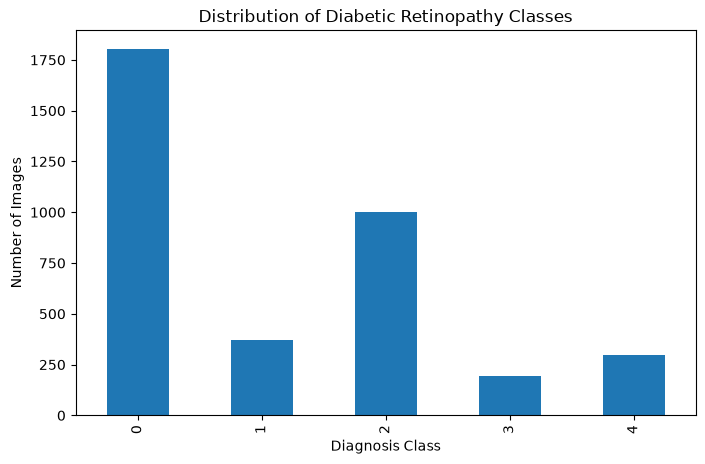

In [10]:
plt.figure(figsize=(8,5))

class_counts.plot(kind='bar')

plt.title("Distribution of Diabetic Retinopathy Classes")

plt.xlabel("Diagnosis Class")

plt.ylabel("Number of Images")

plt.show()

# Image-Level Exploratory Data Analysis
## Display Sample Images from the Dataset

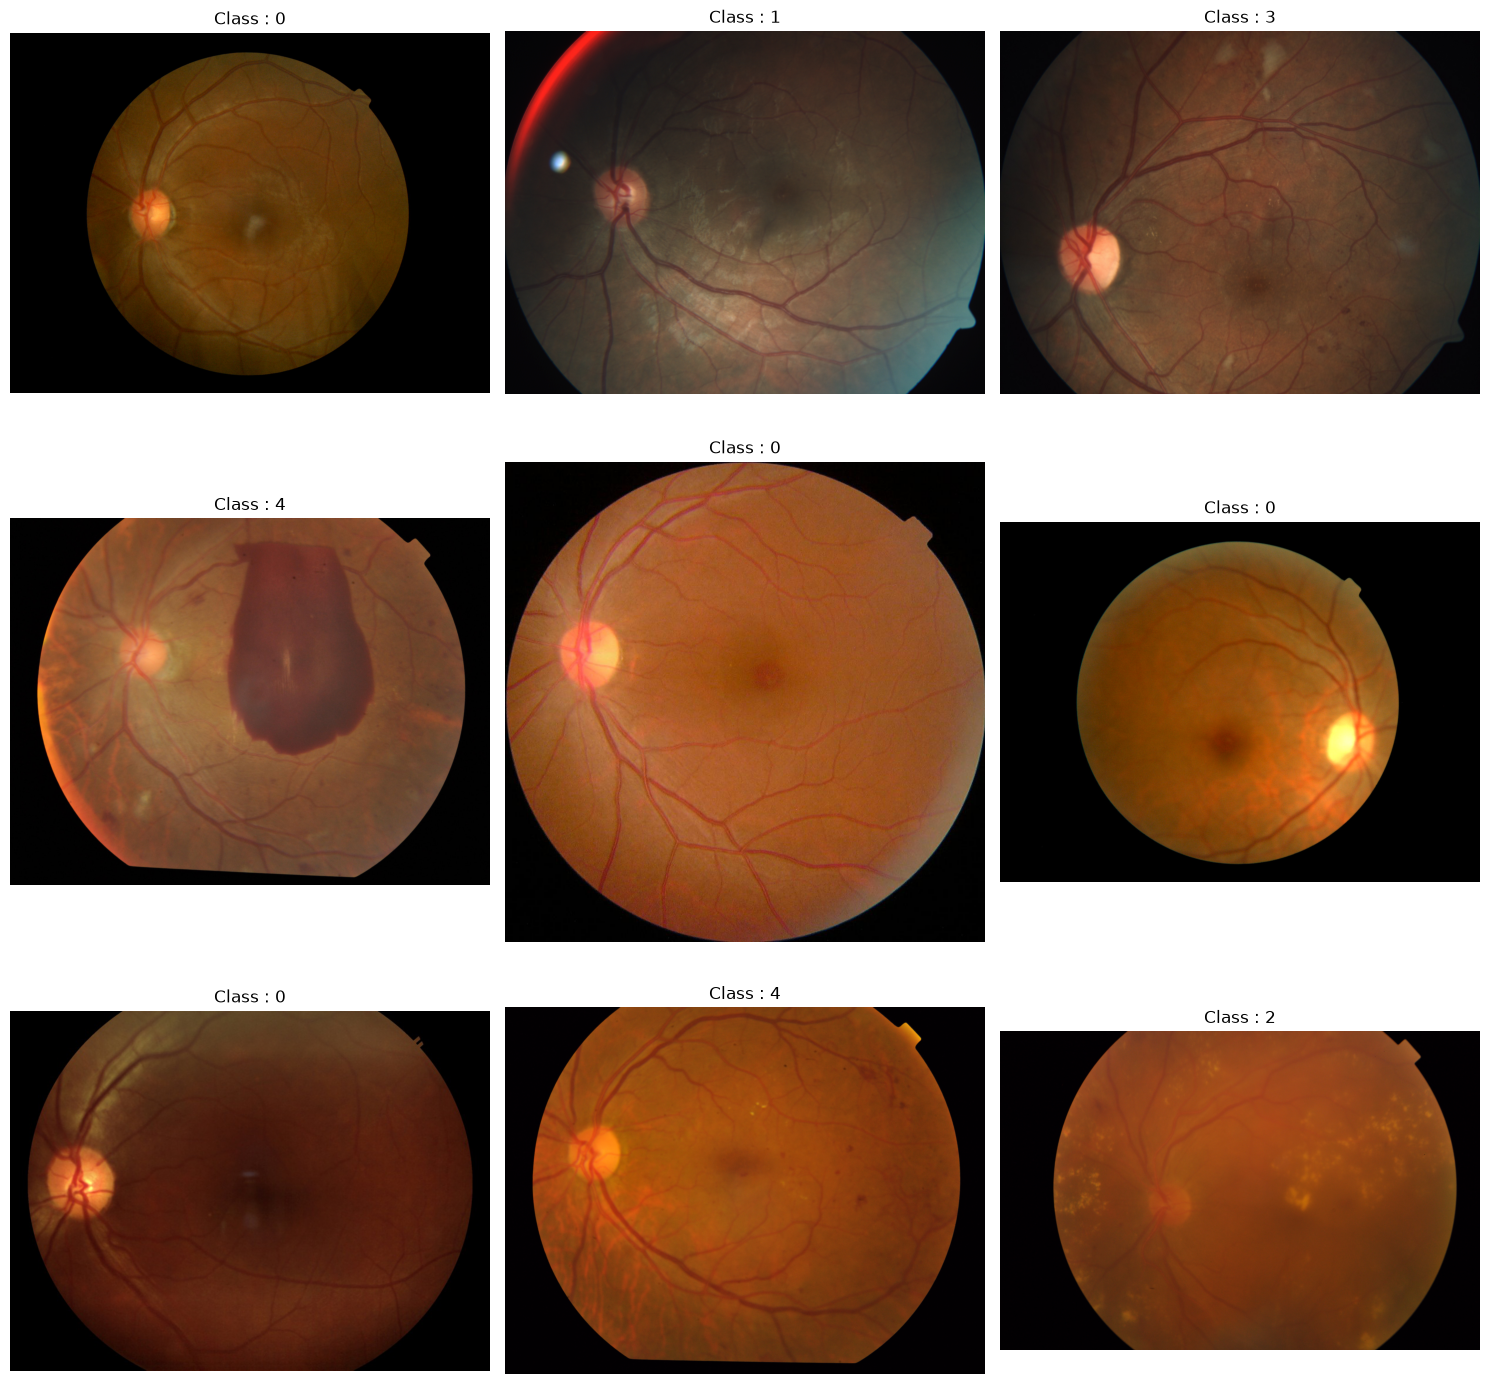

In [11]:
# Display 9 random retinal images

sample_images = df.sample(9, random_state=42)

plt.figure(figsize=(15, 15))

for i, (_, row) in enumerate(sample_images.iterrows()):
    
    image_path = os.path.join(TRAIN_IMAGES, row["id_code"] + ".png")
    
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    plt.subplot(3,3,i+1)
    plt.imshow(image)
    plt.title(f"Class : {row['diagnosis']}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## One Sample Image from Each DR Severity Class

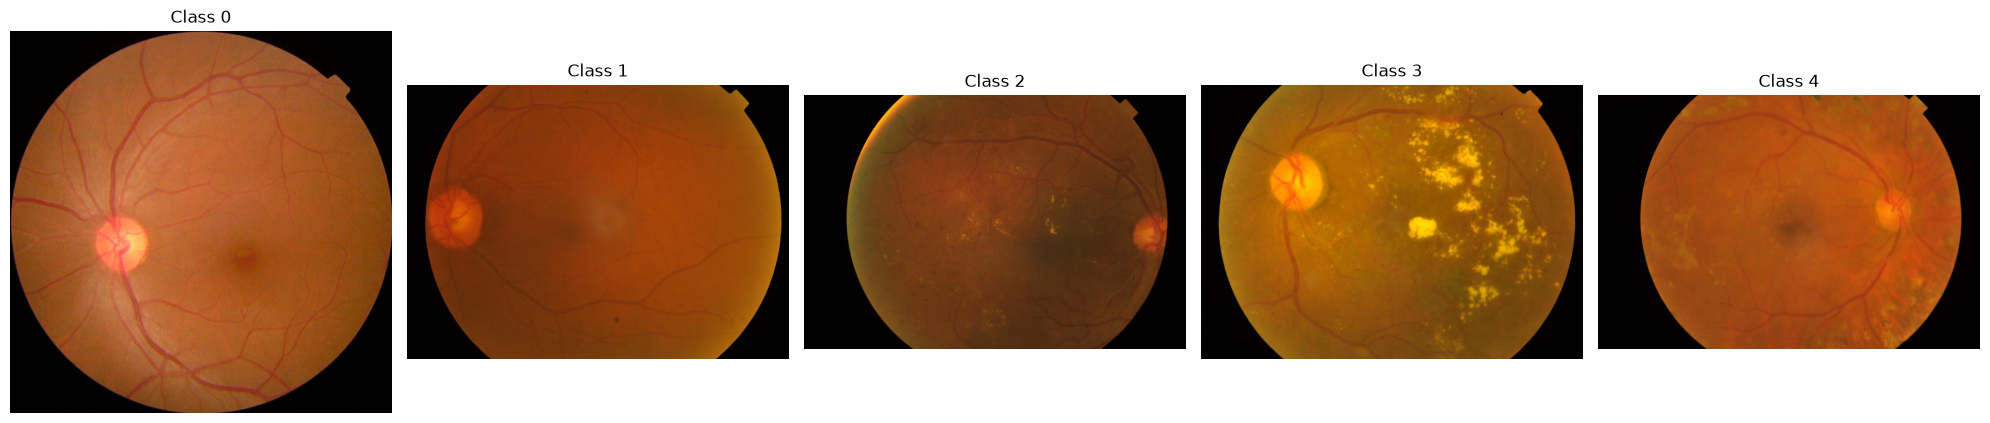

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(20,5))

for diagnosis in range(5):
    
    sample = df[df["diagnosis"] == diagnosis].iloc[0]
    
    image_path = os.path.join(TRAIN_IMAGES, sample["id_code"] + ".png")
    
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    axes[diagnosis].imshow(image)
    axes[diagnosis].set_title(f"Class {diagnosis}")
    axes[diagnosis].axis("off")

plt.tight_layout()
plt.show()

## Image Resolution Analysis

In [13]:
image_sizes = []

for image_name in df["id_code"]:
    
    image_path = os.path.join(TRAIN_IMAGES, image_name + ".png")
    
    image = cv2.imread(image_path)
    
    h, w, _ = image.shape
    
    image_sizes.append((w, h))

image_sizes[:10]

[(3216, 2136),
 (3216, 2136),
 (2416, 1736),
 (1050, 1050),
 (2048, 1536),
 (3388, 2588),
 (2588, 1958),
 (3216, 2136),
 (2588, 1958),
 (2416, 1736)]

In [14]:
from collections import Counter

size_counts = Counter(image_sizes)

print("Unique Image Sizes:", len(size_counts))

size_counts.most_common(10)

Unique Image Sizes: 17


[((1050, 1050), 974),
 ((2416, 1736), 638),
 ((2588, 1958), 533),
 ((3216, 2136), 410),
 ((2048, 1536), 351),
 ((819, 614), 287),
 ((3388, 2588), 141),
 ((1504, 1000), 92),
 ((1844, 1226), 61),
 ((4288, 2848), 52)]

In [15]:
widths = [size[0] for size in image_sizes]
heights = [size[1] for size in image_sizes]

print("Minimum Width :", min(widths))
print("Maximum Width :", max(widths))

print("Minimum Height :", min(heights))
print("Maximum Height :", max(heights))

Minimum Width : 474
Maximum Width : 4288
Minimum Height : 358
Maximum Height : 2848


In [16]:
corrupted = []

for image_name in df["id_code"]:
    
    image_path = os.path.join(TRAIN_IMAGES, image_name + ".png")
    
    image = cv2.imread(image_path)
    
    if image is None:
        corrupted.append(image_name)

print("Corrupted Images :", len(corrupted))

Corrupted Images : 0


In [ ]:
import matplotlib.pyplot as plt

# ============================================================
# APTOS 2019 DATASET - CLASS-WISE DISTRIBUTION AND DATASET SPLIT
# ============================================================

# Actual class-wise distribution used in our project
classes = [
    "No DR (0)",
    "Mild DR (1)",
    "Moderate DR (2)",
    "Severe DR (3)",
    "Proliferative DR (4)"
]

total_images = [1805, 370, 999, 193, 295]
training = [1263, 259, 699, 135, 207]
validation = [271, 55, 150, 29, 44]
test = [271, 56, 150, 29, 44]

# Total row
total_row = [
    sum(total_images),
    sum(training),
    sum(validation),
    sum(test)
]

# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5.8))

# Remove axes
ax.axis("off")

# Table data
table_data = []

for i in range(len(classes)):
    table_data.append([
        classes[i],
        f"{total_images[i]:,}",
        f"{training[i]:,}",
        f"{validation[i]:,}",
        f"{test[i]:,}"
    ])

# Add total row
table_data.append([
    "Total",
    f"{total_row[0]:,}",
    f"{total_row[1]:,}",
    f"{total_row[2]:,}",
    f"{total_row[3]:,}"
])

# Column headers
columns = [
    "Class",
    "Total Images",
    "Training",
    "Validation",
    "Test"
]

# ============================================================
# CREATE TABLE
# ============================================================

table = ax.table(
    cellText=table_data,
    colLabels=columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[0.30, 0.20, 0.18, 0.18, 0.14]
)

# Font settings
table.auto_set_font_size(False)
table.set_fontsize(14)

# Increase row height
table.scale(1, 2.0)

# ============================================================
# FORMAT TABLE
# ============================================================

n_rows = len(table_data) + 1
n_cols = len(columns)

for (row, col), cell in table.get_celld().items():

    # Remove all borders first
    cell.set_edgecolor("white")
    cell.set_linewidth(0)

    # Serif font similar to research-paper tables
    cell.get_text().set_fontfamily("serif")

    # Header
    if row == 0:
        cell.get_text().set_fontweight("bold")
        cell.set_facecolor("white")

    # Total row
    elif row == len(table_data):
        cell.get_text().set_fontweight("bold")
        cell.set_facecolor("white")

    # Normal cells
    else:
        cell.set_facecolor("white")

# ============================================================
# ADD HORIZONTAL RULES
# ============================================================

# Determine table position
fig.canvas.draw()

# Get bounding box of table
bbox = table.get_window_extent(fig.canvas.get_renderer())
bbox = bbox.transformed(ax.transAxes.inverted())

left = bbox.x0
right = bbox.x1
bottom = bbox.y0
top = bbox.y1

# Header bottom line
header_height = (top - bottom) / n_rows
header_bottom = top - header_height

# Total row top line
total_top = bottom + header_height

# Top rule
ax.plot(
    [left, right],
    [top, top],
    transform=ax.transAxes,
    linewidth=1.2,
    color="black"
)

# Header bottom rule
ax.plot(
    [left, right],
    [header_bottom, header_bottom],
    transform=ax.transAxes,
    linewidth=0.8,
    color="black"
)

# Line above total row
ax.plot(
    [left, right],
    [total_top, total_top],
    transform=ax.transAxes,
    linewidth=0.8,
    color="black"
)

# Bottom rule
ax.plot(
    [left, right],
    [bottom, bottom],
    transform=ax.transAxes,
    linewidth=1.2,
    color="black"
)

# ============================================================
# TITLE
# ============================================================

ax.set_title(
    "CLASS-WISE DISTRIBUTION AND DATASET SPLIT",
    fontsize=17,
    fontfamily="serif",
    fontweight="bold",
    pad=20
)

# ============================================================
# SAVE IMAGE
# ============================================================

plt.savefig(
    "aptos_dataset_split.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()